# 08 — Comparer les runs subset

Lit `checkpoints/<run>/history.json` (et `gold_sanity.json` s'il existe) pour
comparer des recettes entraînées sur **le même 25 % du train** (val pleine).

Les runs à comparer sont listés en dur dans `RUNS` (cellule suivante) :
commenter une ligne suffit pour retirer un checkpoint de l'analyse.

Le checkpoint se pilote sur la **val macro-AUC**. Le gold (58) et surtout
**Lateral OA / MCL** sont le signal attendu du T1 — un écart de macro-AUC
**&lt; 0,01** sur un subset de 924 études = bruit.

Tu peux relancer les cellules pendant qu'un run tourne encore : l'historique
s'écrit à chaque epoch.

In [298]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "checkpoints").exists() else Path.cwd().parent
CKPT = ROOT / "checkpoints"

# Checkpoints a comparer (noms de dossiers sous checkpoints/).
# Commenter une ligne pour l'exclure de l'analyse.
RUNS = [
    "subset_v8_frac025",
    "subset_v8_crop130_frac025",
    "subset_v10_crop130_frac025",
    "subset_v11_crop130_frac025",
    "subset_v11_crop130_frac025_A+B",
]
REF = "subset_v8_frac025"  # baseline pour les deltas

FOCUS = ["Lateral OA", "MCL", "ACL", "Medial Meniscus"]
TARGETS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA",
    "Lateral OA", "PF OA", "Effusion", "Synovitis", "Baker's",
    "Contusion", "Fracture",
]

print("ROOT", ROOT)
print("checkpoints", CKPT.exists())

ROOT c:\Users\sulta\Documents\RSNA-comp
checkpoints True


In [299]:
def load_run(name: str) -> dict | None:
    d = CKPT / name
    hist_p = d / "history.json"
    if not hist_p.exists():
        print(f"  skip {name} : pas de history.json (pas encore d'epoch finie)")
        return None
    hist = pd.DataFrame(json.loads(hist_p.read_text(encoding="utf-8")))
    if hist.empty:
        print(f"  skip {name} : history.json vide")
        return None
    gold = None
    gp = d / "gold_sanity.json"
    if gp.exists():
        gold = json.loads(gp.read_text(encoding="utf-8"))
    cfg = {}
    last_p, best_p = d / "last.pt", d / "best.pt"
    # config : copie YAML sauvee a cote si presente, sinon on lit le ckpt plus tard
    uids = []
    up = d / "train_uids.txt"
    if up.exists():
        uids = [ln.strip() for ln in up.read_text(encoding="utf-8").splitlines() if ln.strip()]
    best_idx = hist["val_macro_auc"].idxmax()
    best_row = hist.loc[best_idx]
    return {
        "name": name,
        "dir": d,
        "hist": hist,
        "gold": gold,
        "uids": uids,
        "done": gp.exists(),
        "best_epoch": int(best_row["epoch"]),
        "best_val": float(best_row["val_macro_auc"]),
        "best_gold": float(best_row["gold_macro_auc"]) if "gold_macro_auc" in hist.columns and pd.notna(best_row.get("gold_macro_auc")) else None,
        "last_epoch": int(hist["epoch"].max()),
    }


wanted = list(RUNS)
runs = []
print("runs demandes :", wanted)
for name in wanted:
    rec = load_run(name)
    if rec is None:
        continue
    runs.append(rec)
    gold_txt = f"gold {rec['best_gold']:.3f}" if rec["best_gold"] is not None else "gold n/a"
    etat = "termine" if rec["done"] else f"en cours (epoch {rec['last_epoch']})"
    print(f"  {name}: {etat} | best val {rec['best_val']:.4f} @ ep {rec['best_epoch']} | {gold_txt} | n_train {len(rec['uids']) or '?'}")

if not runs:
    raise SystemExit("aucun history.json — lance d'abord un train subset")

runs demandes : ['subset_v8_frac025', 'subset_v8_crop130_frac025', 'subset_v10_crop130_frac025', 'subset_v11_crop130_frac025', 'subset_v11_crop130_frac025_A+B']
  subset_v8_frac025: termine | best val 0.6896 @ ep 10 | gold 0.698 | n_train 924
  subset_v8_crop130_frac025: termine | best val 0.7517 @ ep 10 | gold 0.734 | n_train 924
  subset_v10_crop130_frac025: termine | best val 0.7938 @ ep 9 | gold 0.809 | n_train 924
  subset_v11_crop130_frac025: termine | best val 0.7794 @ ep 8 | gold 0.763 | n_train 924
  skip subset_v11_crop130_frac025_A+B : pas de history.json (pas encore d'epoch finie)


## Tableau résumé

Meilleure epoch = argmax de la val macro-AUC (comme le `best.pt`).

In [300]:
rows = []
for r in runs:
    last = r["hist"].iloc[-1]
    rows.append({
        "run": r["name"],
        "etat": "termine" if r["done"] else f"epoch {r['last_epoch']}",
        "n_train": len(r["uids"]) or None,
        "best_epoch": r["best_epoch"],
        "best_val_auc": r["best_val"],
        "best_gold_auc": r["best_gold"],
        "last_train_loss": float(last["loss"]),
        "last_val_loss": float(last["val_loss"]) if "val_loss" in last else None,
        "last_val_auc": float(last["val_macro_auc"]),
    })
summary = pd.DataFrame(rows).set_index("run")
display(summary.round(4))

if REF in summary.index and len(summary) > 1:
    print("\ndelta vs", REF, "(best val AUC)")
    ref_val = summary.loc[REF, "best_val_auc"]
    for name, row in summary.iterrows():
        if name == REF:
            continue
        d = row["best_val_auc"] - ref_val
        print(f"  {name}: {d:+.4f}  {'(bruit, <0.01)' if abs(d) < 0.01 else ''}")

,etat,n_train,best_epoch,best_val_auc,best_gold_auc,last_train_loss,last_val_loss,last_val_auc
run,,,,,,,,
subset_v8_frac025,termine,924,10,0.6896,0.6976,0.4712,0.4729,0.6896
subset_v8_crop130_frac025,termine,924,10,0.7517,0.7339,0.4146,0.4455,0.7517
subset_v10_crop130_frac025,termine,924,9,0.7938,0.8088,0.3952,0.4151,0.7938
subset_v11_crop130_frac025,termine,924,8,0.7794,0.7629,0.4058,0.4262,0.7793



delta vs subset_v8_frac025 (best val AUC)
  subset_v8_crop130_frac025: +0.0621  
  subset_v10_crop130_frac025: +0.1042  
  subset_v11_crop130_frac025: +0.0898  


## Courbes (tous les runs superposés)

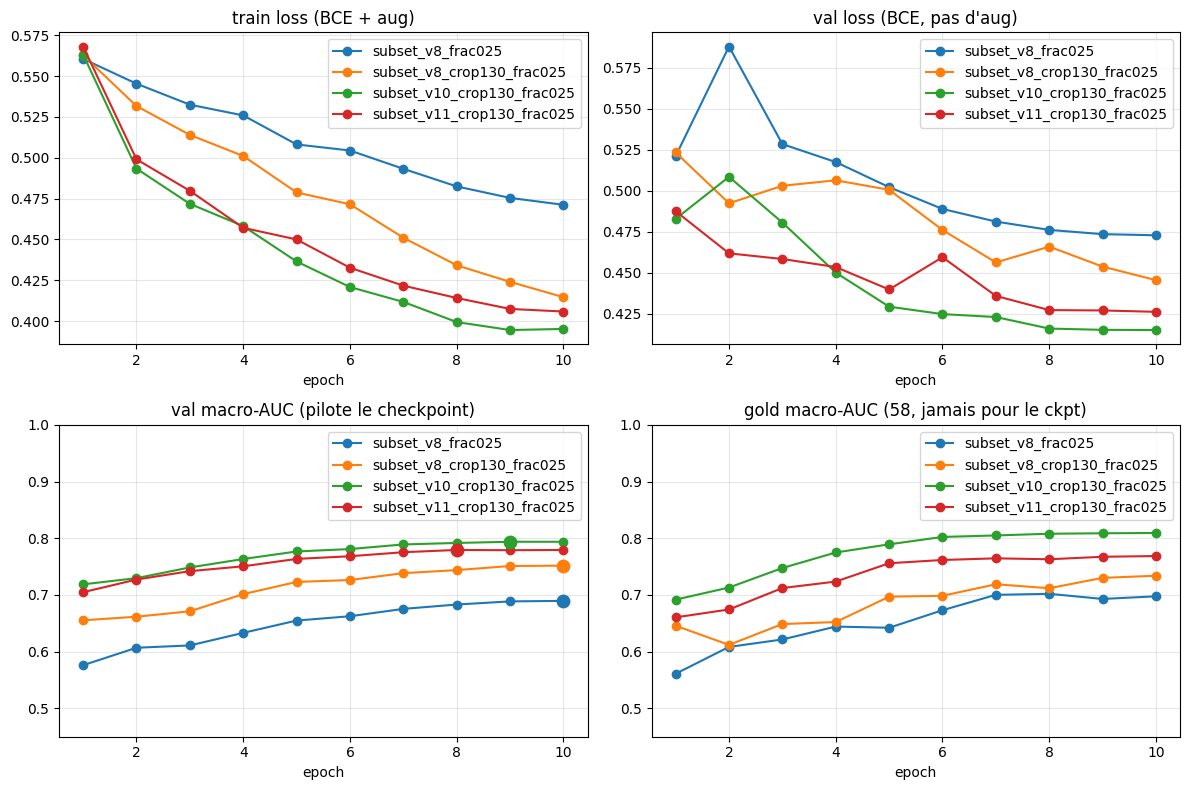

In [301]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for r in runs:
    h = r["hist"]
    axes[0, 0].plot(h.epoch, h.loss, marker="o", label=r["name"])
    if "val_loss" in h.columns:
        axes[0, 1].plot(h.epoch, h.val_loss, marker="o", label=r["name"])
    axes[1, 0].plot(h.epoch, h.val_macro_auc, marker="o", label=r["name"])
    if "gold_macro_auc" in h.columns:
        axes[1, 1].plot(h.epoch, h.gold_macro_auc, marker="o", label=r["name"])
    axes[1, 0].scatter([r["best_epoch"]], [r["best_val"]], s=80, zorder=5)

axes[0, 0].set_title("train loss (BCE + aug)")
axes[0, 1].set_title("val loss (BCE, pas d'aug)")
axes[1, 0].set_title("val macro-AUC (pilote le checkpoint)")
axes[1, 1].set_title("gold macro-AUC (58, jamais pour le ckpt)")
for ax in axes.ravel():
    ax.set_xlabel("epoch")
    ax.grid(True, alpha=0.3)
    ax.legend()
axes[1, 0].set_ylim(0.45, 1.0)
axes[1, 1].set_ylim(0.45, 1.0)
plt.tight_layout()
plt.show()

## AUC par cible à la meilleure epoch

Barres groupées = comparaison directe. Les cibles **FOCUS** (T1 : anatomie) sont en gras dans le tableau.

,subset_v8_frac025,subset_v8_crop130_frac025,subset_v10_crop130_frac025,subset_v11_crop130_frac025,d_subset_v8_crop130_frac025,d_subset_v10_crop130_frac025,d_subset_v11_crop130_frac025
ACL,0.651000,0.679000,0.727000,0.735000,0.028000,0.076000,0.084000
MCL,0.636000,0.676000,0.715000,0.702000,0.040000,0.079000,0.066000
Medial Meniscus,0.687000,0.788000,0.795000,0.867000,0.100000,0.108000,0.180000
Lateral Meniscus,0.672000,0.730000,0.799000,0.770000,0.058000,0.128000,0.099000
Medial OA,0.744000,0.791000,0.832000,0.819000,0.047000,0.088000,0.074000
Lateral OA,0.679000,0.729000,0.769000,0.747000,0.050000,0.090000,0.068000
PF OA,0.665000,0.720000,0.793000,0.732000,0.055000,0.129000,0.067000
Effusion,0.818000,0.809000,0.799000,0.783000,-0.010000,-0.019000,-0.035000
Synovitis,0.706000,0.826000,0.843000,0.836000,0.120000,0.138000,0.130000
Baker's,0.779000,0.788000,0.847000,0.783000,0.009000,0.069000,0.004000


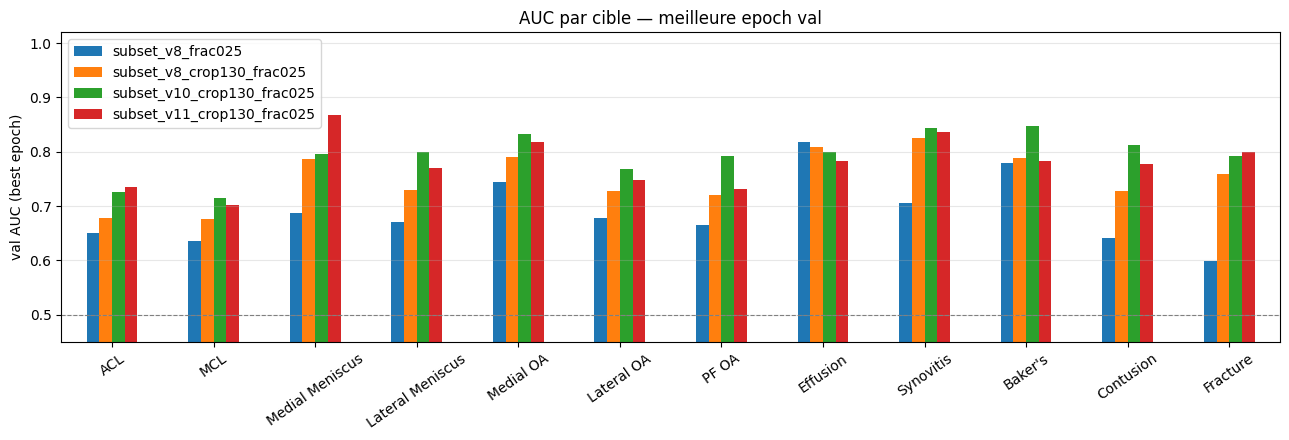

In [302]:
per = {}
for r in runs:
    row = r["hist"].loc[r["hist"]["val_macro_auc"].idxmax()]
    per[r["name"]] = {t: float(row[f"auc_{t}"]) for t in TARGETS if f"auc_{t}" in row.index}
per_df = pd.DataFrame(per).reindex(TARGETS)

if REF in per_df.columns:
    others = [c for c in per_df.columns if c != REF]
    for c in others:
        per_df[f"d_{c}"] = per_df[c] - per_df[REF]

display(per_df.round(3).style.apply(
    lambda s: ["font-weight: bold" if s.name in FOCUS else "" for _ in s],
    axis=1,
))

ax = per_df[[r["name"] for r in runs]].plot(
    kind="bar", figsize=(13, 4.5), rot=35,
)
ax.set_ylabel("val AUC (best epoch)")
ax.set_ylim(0.45, 1.02)
ax.set_title("AUC par cible — meilleure epoch val")
ax.axhline(0.5, color="gray", lw=0.8, ls="--")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Delta par cible vs v8

Positif = le run bat la référence sur cette cible. Le T1 devrait surtout
bouger Lateral OA / MCL / ménisques, pas Baker / Effusion (déjà portés par le fluide).

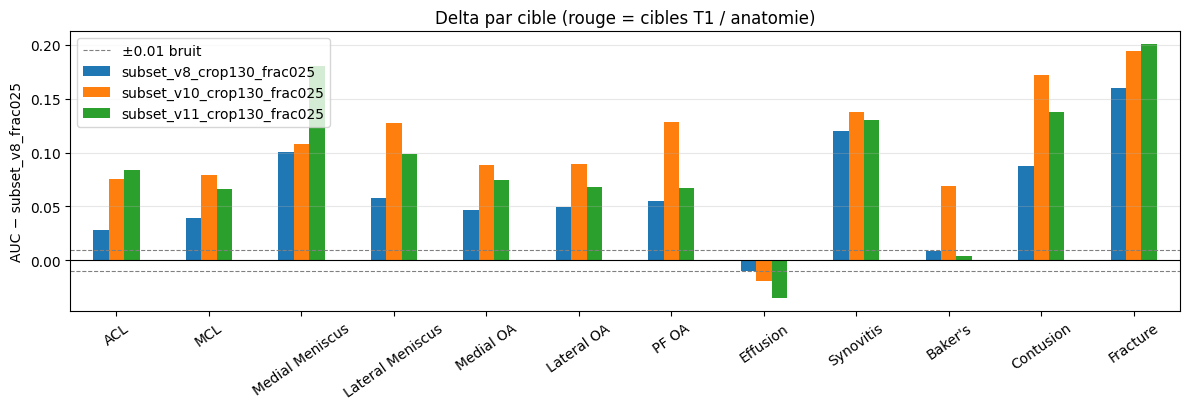

FOCUS (T1 attendu) :


,subset_v8_frac025,subset_v8_crop130_frac025,subset_v10_crop130_frac025,subset_v11_crop130_frac025,d_subset_v8_crop130_frac025,d_subset_v10_crop130_frac025,d_subset_v11_crop130_frac025
Lateral OA,0.679,0.729,0.769,0.747,0.050,0.090,0.068
MCL,0.636,0.676,0.715,0.702,0.040,0.079,0.066
ACL,0.651,0.679,0.727,0.735,0.028,0.076,0.084
Medial Meniscus,0.687,0.788,0.795,0.867,0.100,0.108,0.180


In [303]:
delta_cols = [c for c in per_df.columns if c.startswith("d_")]
if not delta_cols:
    print(f"pas de delta : il faut au moins 2 runs, dont REF={REF!r} charge.")
else:
    fig, ax = plt.subplots(figsize=(12, 4.2))
    d = per_df[delta_cols].copy()
    d.columns = [c[2:] for c in d.columns]
    colors_focus = ["#c44e52" if t in FOCUS else "#4c72b0" for t in d.index]
    # un seul comparateur : barres simples ; plusieurs : grouped
    if d.shape[1] == 1:
        ax.bar(range(len(d)), d.iloc[:, 0], color=colors_focus, edgecolor="black", lw=0.3)
        ax.set_xticks(range(len(d)))
        ax.set_xticklabels(d.index, rotation=35, ha="right")
        ax.set_ylabel(f"AUC {d.columns[0]} − {REF}")
    else:
        d.plot(kind="bar", ax=ax, rot=35)
        ax.set_ylabel(f"AUC − {REF}")
    ax.axhline(0.0, color="black", lw=0.8)
    ax.axhline(0.01, color="gray", ls="--", lw=0.8, label="±0.01 bruit")
    ax.axhline(-0.01, color="gray", ls="--", lw=0.8)
    ax.set_title("Delta par cible (rouge = cibles T1 / anatomie)")
    ax.grid(True, axis="y", alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    print("FOCUS (T1 attendu) :")
    display(per_df.loc[FOCUS].round(3))

## Courbes des cibles FOCUS (toutes les epochs)

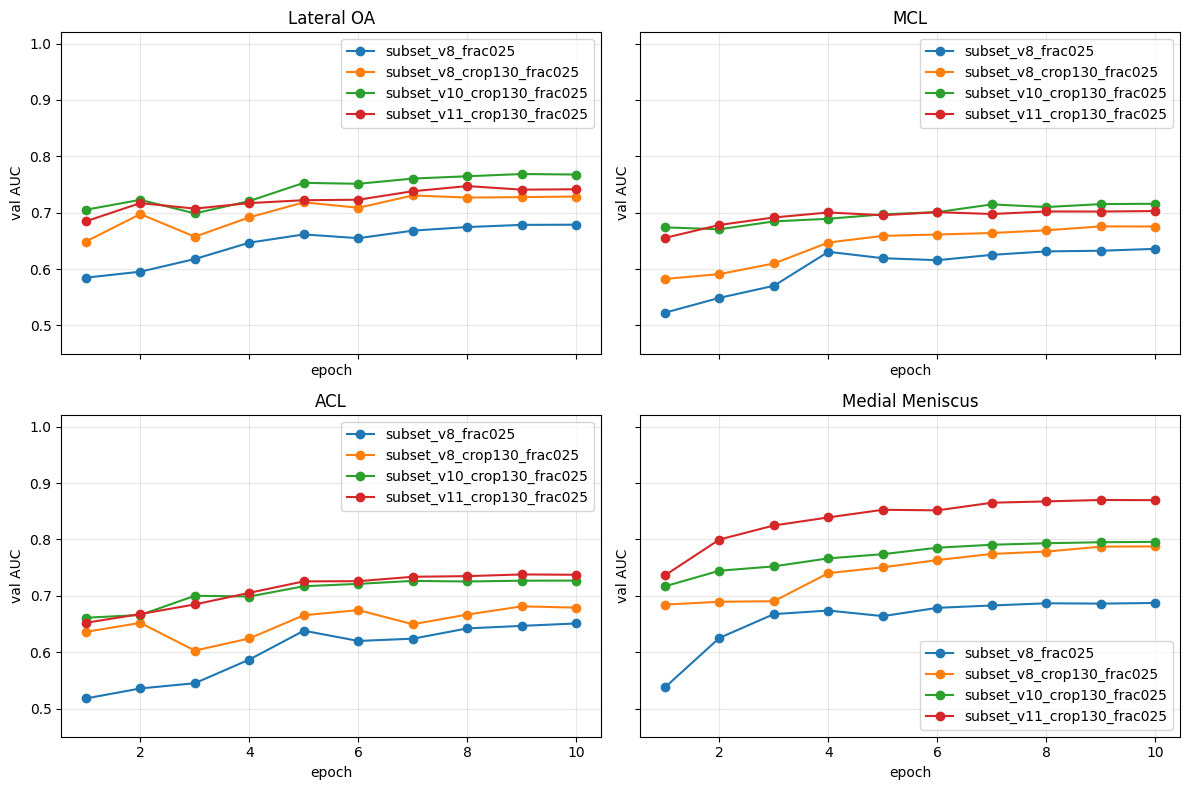

In [304]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, tgt in zip(axes.ravel(), FOCUS):
    col = f"auc_{tgt}"
    for r in runs:
        h = r["hist"]
        if col not in h.columns:
            continue
        ax.plot(h.epoch, h[col], marker="o", label=r["name"])
    ax.set_title(tgt)
    ax.set_ylim(0.45, 1.02)
    ax.grid(True, alpha=0.3)
    ax.legend()
    ax.set_xlabel("epoch")
    ax.set_ylabel("val AUC")
plt.tight_layout()
plt.show()

## Même subset ? (train_uids)

Les YAML subset partagent `train_frac_seed: 42`. L'overlap doit être 100 %.

In [305]:
uid_sets = {r["name"]: set(r["uids"]) for r in runs if r["uids"]}
if len(uid_sets) < 2:
    print("pas assez de train_uids.txt pour comparer (normal si un run n'a pas demarre)")
else:
    names = list(uid_sets)
    a, b = names[0], names[1]
    sa, sb = uid_sets[a], uid_sets[b]
    print(f"{a}: {len(sa)}  |  {b}: {len(sb)}")
    print(f"intersection {len(sa & sb)}  |  seulement {a} {len(sa - sb)}  |  seulement {b} {len(sb - sa)}")
    if sa == sb:
        print("OK : exactement les memes etudes train")
    else:
        print("ATTENTION : subsets differents, la comparaison d'archi n'est plus propre")

subset_v8_frac025: 924  |  subset_v8_crop130_frac025: 924
intersection 924  |  seulement subset_v8_frac025 0  |  seulement subset_v8_crop130_frac025 0
OK : exactement les memes etudes train


## Sanity gold du `best.pt` (si le run est fini)

`gold_sanity.json` n'est écrit qu'à la **fin** du script. Pendant l'entraînement,
utilise la courbe `gold_macro_auc` ci-dessus (loggée chaque epoch).

subset_v8_frac025: macro-AUC gold 0.6976  (best epoch 10)
subset_v8_crop130_frac025: macro-AUC gold 0.7339  (best epoch 10)
subset_v10_crop130_frac025: macro-AUC gold 0.8088  (best epoch 9)
subset_v11_crop130_frac025: macro-AUC gold 0.7629  (best epoch 8)


,subset_v8_frac025,subset_v8_crop130_frac025,subset_v10_crop130_frac025,subset_v11_crop130_frac025,d_subset_v8_crop130_frac025,d_subset_v10_crop130_frac025,d_subset_v11_crop130_frac025
ACL,0.555,0.626,0.772,0.727,0.072,0.218,0.172
MCL,0.552,0.562,0.703,0.558,0.010,0.151,0.006
Medial Meniscus,0.680,0.755,0.715,0.833,0.075,0.035,0.153
Lateral Meniscus,0.727,0.712,0.754,0.707,-0.016,0.027,-0.020
Medial OA,0.750,0.868,0.946,0.944,0.119,0.196,0.195
Lateral OA,0.768,0.656,0.774,0.691,-0.112,0.006,-0.077
PF OA,0.630,0.659,0.793,0.692,0.029,0.163,0.062
Effusion,0.930,0.868,0.745,0.768,-0.062,-0.185,-0.163
Synovitis,0.719,0.746,0.827,0.711,0.027,0.108,-0.008
Baker's,0.799,0.866,0.937,0.824,0.067,0.138,0.025


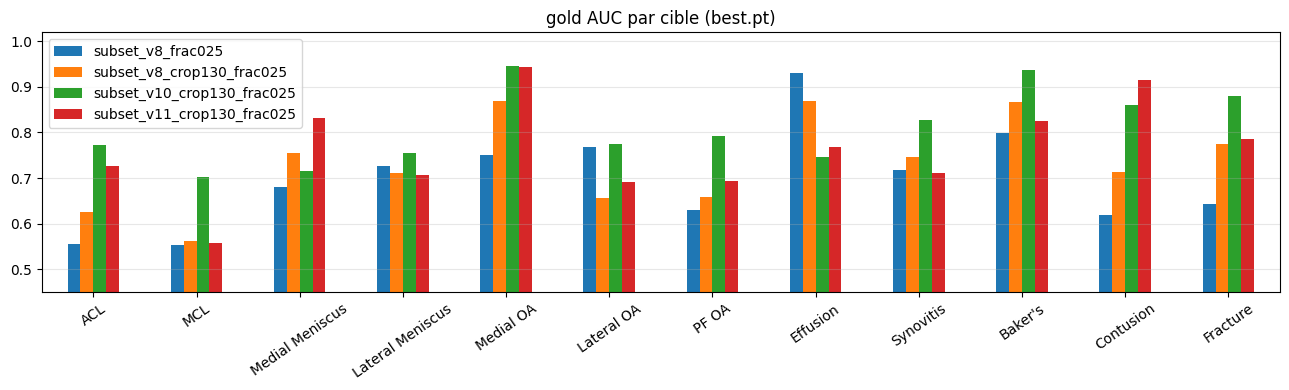

In [306]:
gcols = {}
for r in runs:
    if not r["gold"]:
        print(f"{r['name']}: pas encore de gold_sanity.json")
        continue
    g = r["gold"]
    print(f"{r['name']}: macro-AUC gold {g['macro_auc']:.4f}  (best epoch {g.get('epoch', '?')})")
    gcols[r["name"]] = pd.Series(g["per_target"])
if gcols:
    gdf = pd.DataFrame(gcols).reindex(TARGETS)
    if REF in gdf.columns:
        for c in gdf.columns:
            if c != REF:
                gdf[f"d_{c}"] = gdf[c] - gdf[REF]
    display(gdf.round(3))
    gdf[[r["name"] for r in runs if r["name"] in gdf.columns]].plot(
        kind="bar", figsize=(13, 4), rot=35, title="gold AUC par cible (best.pt)",
    )
    plt.ylim(0.45, 1.02)
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

## Comment lire

1. **Val macro-AUC** : critère principal. Δ &lt; 0,01 → on ne déclare pas de gagnant.
2. **Lateral OA / MCL** : si v9 gagne surtout là, le T1 sert. Si Baker/Effusion
   bougent et pas l'anatomie, ce n'est pas le levier T1.
3. **Gold** : n=58, très bruité. Un écart gold sans écart val n'est pas une preuve.
4. Si v9 gagne clairement : relancer `configs/kneenet_v9.yaml` sur **tout** le train.
   Sinon garder v8 (`configs/kneenet_v8.yaml`) pour la soumission.

Pour rafraîchir pendant que v9 tourne : **re-exécuter à partir de la cellule Load**.